# Free Cash Flow Charts

Charts of the free cash flow history built by `01_fcf_history.ipynb`. Run that notebook first: it saves the table read here.

Values are converted from thousands to **billions** or **millions of reais** in each chart. Colors follow one rule across the notebook: blue = operating cash flow (CFO), orange = capex, green = free cash flow (FCF).

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from cvm_valuation.config import DATA_DIR

CFO_COLOR = "#2a78d6"
CAPEX_COLOR = "#eb6834"
FCF_COLOR = "#1baf7a"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e1e0d9"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

history_full = pd.read_csv(DATA_DIR / "history_full.csv")
investable = history_full[history_full["IS_INVESTABLE"]]
print(f"{investable['CD_CVM'].nunique()} investable companies, years {history_full['YEAR'].min()}–{history_full['YEAR'].max()}")

232 investable companies, years 2010–2025


## 2. All investable companies

Sum of the operating cash flow, capex and FCF of the companies that are investable **today**, in each year. Two cautions:

- The set of companies changes over time (IPOs enter the sum in their first year), so part of the growth is new companies, not growth of the same ones.
- A few large companies (Petrobras, Vale) dominate the sum.

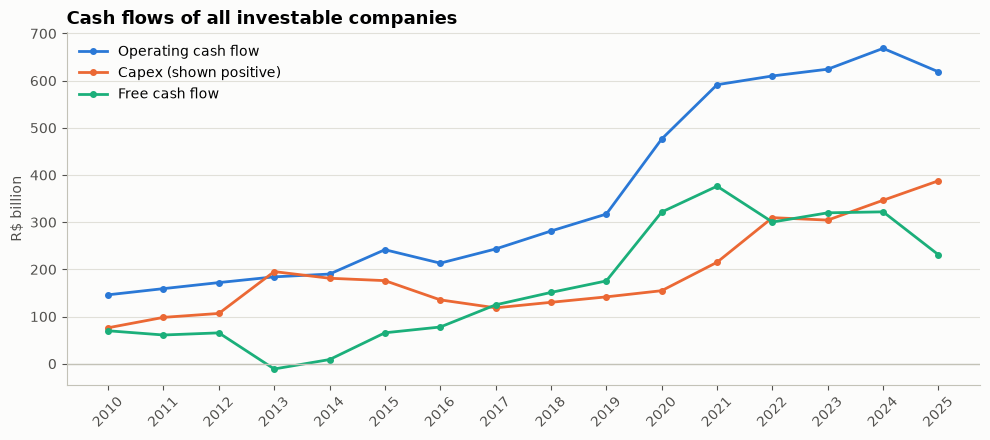

,CFO,CAPEX,FCF
YEAR,,,
2010,146.1,-76.2,69.9
2011,159.2,-98.3,60.9
2012,172.0,-106.6,65.4
2013,184.1,-195.3,-11.1
2014,190.1,-181.2,8.9
2015,241.7,-176.1,65.6
2016,213.2,-135.4,77.8
2017,243.3,-118.5,124.8
2018,281.3,-130.2,151.1


In [2]:
totals = investable.groupby("YEAR")[["CFO", "CAPEX", "FCF"]].sum() / 1e6   # thousands -> billions

fig, ax = plt.subplots()
ax.plot(totals.index, totals["CFO"], color=CFO_COLOR, marker="o", markersize=4, label="Operating cash flow")
ax.plot(totals.index, -totals["CAPEX"], color=CAPEX_COLOR, marker="o", markersize=4, label="Capex (shown positive)")
ax.plot(totals.index, totals["FCF"], color=FCF_COLOR, marker="o", markersize=4, label="Free cash flow")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Cash flows of all investable companies")
ax.set_ylabel("R$ billion")
ax.set_xticks(totals.index)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

totals.round(1)

### 2.1 How many companies generate cash?

The share of investable companies with a positive FCF in each year. Unlike the sum above, every company counts the same here.

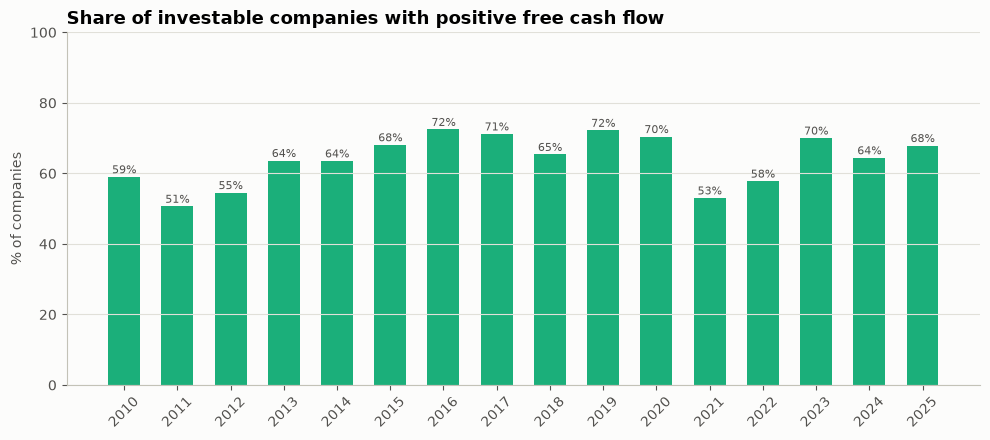

In [3]:
with_fcf = investable[investable["FCF"].notna()]
positive_share = (with_fcf["FCF"] > 0).groupby(with_fcf["YEAR"]).mean() * 100

fig, ax = plt.subplots()
ax.bar(positive_share.index, positive_share, color=FCF_COLOR, width=0.6)
for year, share in positive_share.items():
    ax.text(year, share + 1, f"{share:.0f}%", ha="center", fontsize=8, color=TEXT_COLOR)
ax.set_title("Share of investable companies with positive free cash flow")
ax.set_ylabel("% of companies")
ax.set_ylim(0, 100)
ax.set_xticks(positive_share.index)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 3. Largest cash generators

The investable companies with the largest average FCF over the last three years, the same base the DCF uses.

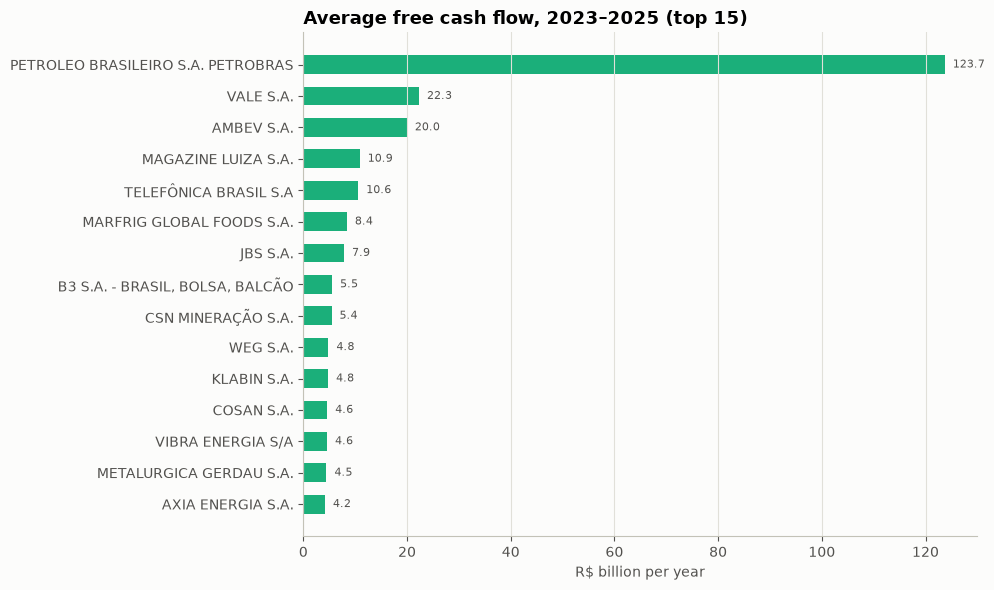

In [4]:
latest_year = history_full["YEAR"].max()
recent = investable[investable["YEAR"] > latest_year - 3]
average_fcf = recent.groupby("DENOM_CIA")["FCF"].mean().sort_values() / 1e6   # billions
top = average_fcf.tail(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top, color=FCF_COLOR, height=0.6)
for name, value in top.items():
    ax.text(value, name, f"  {value:.1f}", va="center", fontsize=8, color=TEXT_COLOR)
ax.set_title(f"Average free cash flow, {latest_year - 2}–{latest_year} (top 15)")
ax.set_xlabel("R$ billion per year")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. One company

`plot_company` draws the cash flows of one company by year (top) and its net debt (bottom). They are two separate charts on purpose: putting both on one chart would need two different y-axes, which makes the reader compare scales that have nothing to do with each other.

In [5]:
def plot_company(code):
    """Plot the cash flows and the net debt of one company, by year."""
    company = history_full[history_full["CD_CVM"] == code].sort_values("YEAR")
    name = company["DENOM_CIA"].iloc[-1]
    years = company["YEAR"]
    width = 0.27

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                      gridspec_kw={"height_ratios": [2, 1]})
    top.bar(years - width, company["CFO"] / 1e3, width, color=CFO_COLOR, label="Operating cash flow")
    top.bar(years, company["CAPEX"] / 1e3, width, color=CAPEX_COLOR, label="Capex")
    top.bar(years + width, company["FCF"] / 1e3, width, color=FCF_COLOR, label="Free cash flow")
    top.axhline(0, color="#c3c2b7", linewidth=1)
    top.set_title(f"{name}: cash flows")
    top.set_ylabel("R$ million")
    top.legend(loc="upper left", ncols=3)

    bottom.plot(years, company["NET_DEBT"] / 1e3, color=TEXT_COLOR, marker="o", markersize=4)
    bottom.axhline(0, color="#c3c2b7", linewidth=1)
    bottom.set_title("Net debt (negative = net cash)")
    bottom.set_ylabel("R$ million")
    bottom.set_xticks(years)
    bottom.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
    columns = ["YEAR", "CFO", "CAPEX", "FCF", "NET_DEBT"]
    return (company[columns].set_index("YEAR") / 1e3).round(1)

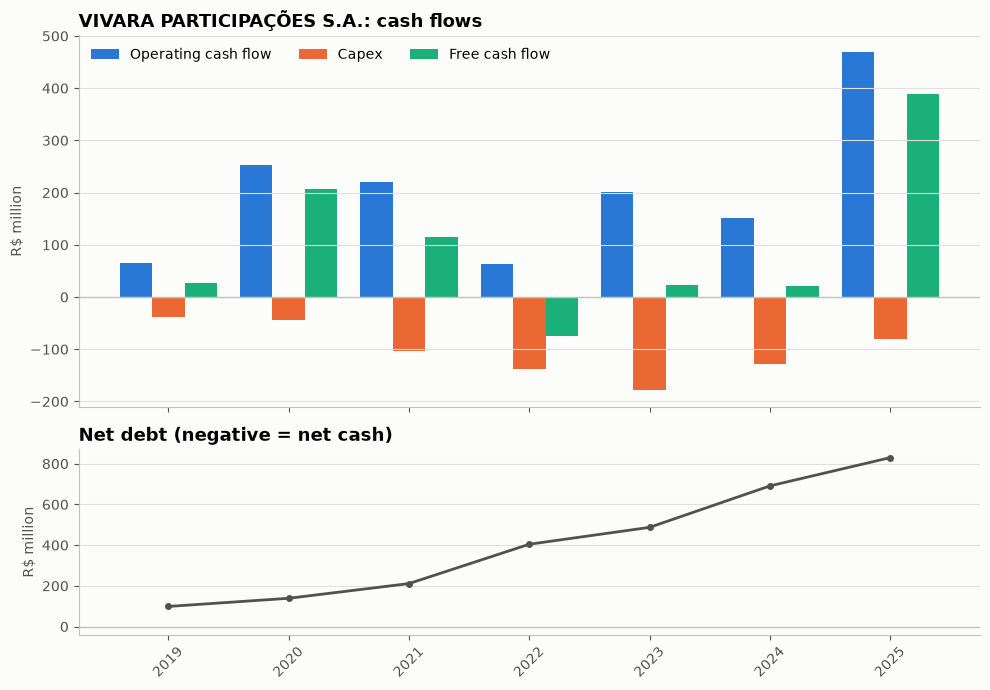

,CFO,CAPEX,FCF,NET_DEBT
YEAR,,,,
2019,65.5,-38.8,26.7,98.8
2020,252.1,-44.7,207.4,138.9
2021,219.8,-104.1,115.7,211.1
2022,63.3,-137.7,-74.4,404.4
2023,201.5,-178.2,23.3,487.3
2024,150.7,-129.0,21.7,691.0
2025,468.9,-80.4,388.4,829.8


In [6]:
plot_company(24805)   # Vivara

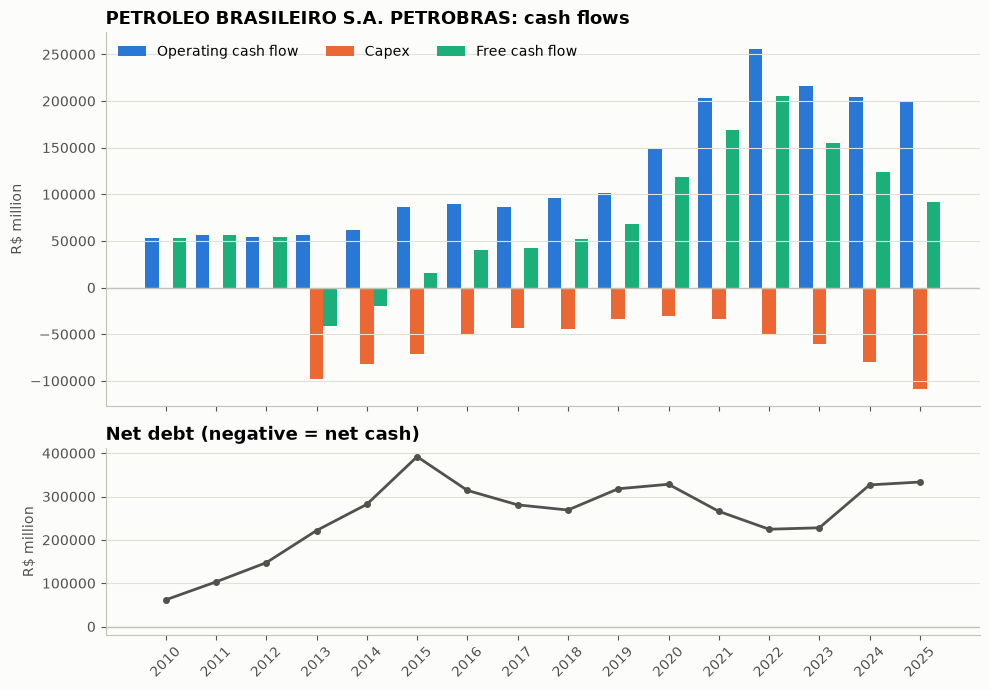

,CFO,CAPEX,FCF,NET_DEBT
YEAR,,,,
2010,53435.4,0.0,53435.4,61574.8
2011,56322.1,0.0,56322.1,102999.0
2012,54145.7,0.0,54145.7,147369.6
2013,56209.3,-97924.6,-41715.3,221548.5
2014,62241.0,-81909.0,-19668.0,282033.0
2015,86407.0,-71311.0,15096.0,391957.0
2016,89709.0,-49289.0,40420.0,314120.0
2017,86467.0,-43614.0,42853.0,280752.0
2018,95846.0,-43987.0,51859.0,268824.0


In [7]:
plot_company(9512)    # Petrobras

To see another company, find its code with `history_full[history_full["DENOM_CIA"].str.contains("NAME", case=False)][["CD_CVM", "DENOM_CIA"]].drop_duplicates()` and call `plot_company(code)`.